!['https://media-cldnry.s-nbcnews.com/image/upload/t_fit-1000w,f_auto,q_auto:best/msnbc/Components/Photos/060324/060324_glacier_hlg_1p.jpg'](https://media-cldnry.s-nbcnews.com/image/upload/t_fit-1000w,f_auto,q_auto:best/msnbc/Components/Photos/060324/060324_glacier_hlg_1p.jpg)

## **Temperature at Many Glacier, MT**
For this activity we'll walk through how to access, open, and display temperature data from NOAA/NCEI using their automated programming interface (API).

Read more about the weather station at Many Glacier, MT: https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USS0013A27S/detail

Throughout the activity, you will be asked to replace text that is inside [square brackets]. When prompted, replace the text and remove the square brackets before running your code cell.

In [1]:
# STEP 0: Import python libraries

import pandas as pd  # working with datafames
import matplotlib.pyplot as plt # plotting
import numpy as np # working with arrays

In [2]:
# STEP 1: Build endpoint request from NOAA/NCEI for Many Glacier, MT

many_glacier_url = (
    "https://www.ncei.noaa.gov/access/services/data/v1"
    "?dataset=daily-summaries"
    "&stations=USS0013A27S"
    "&startDate=1976-09-30"
    "&endDate=2026-11-01"
    "&dataTypes=TOBS,PRCP"
    "&includeStationName=true"
    "&includeStationLocation=1"
    "&units=standard")

many_glacier_url

'https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&stations=USS0013A27S&startDate=1976-09-30&endDate=2026-11-01&dataTypes=TOBS,PRCP&includeStationName=true&includeStationLocation=1&units=standard'

In [3]:
# STEP 2: Open up data using pandas
many_glacier_df = pd.read_csv(many_glacier_url,
                              parse_dates=True,
                              index_col='DATE',
                              na_values=['NaN'])

# Clean up data (drop columns that aren't varying with time)
many_glacier_df = many_glacier_df[['PRCP','TOBS']]
many_glacier_df

,PRCP,TOBS
DATE,,
1976-09-30,NaN,NaN
1976-10-01,NaN,NaN
1976-10-02,NaN,NaN
1976-10-03,NaN,NaN
1976-10-04,NaN,NaN
...,...,...
2026-10-28,0.6,NaN
2026-10-29,0.2,NaN
2026-10-30,0.0,NaN


<Axes: xlabel='DATE'>

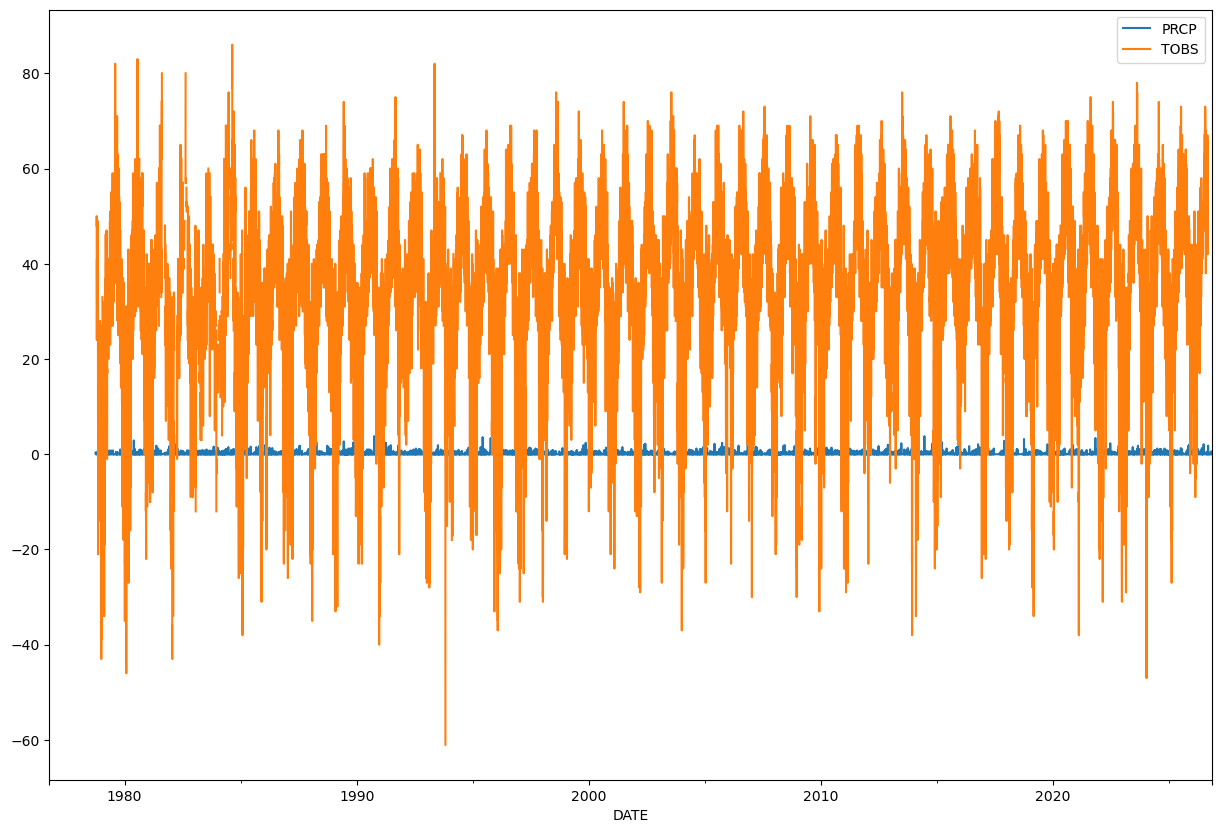

In [4]:
# STEP 3: Plot the data
many_glacier_df.plot(figsize=(15,10))

In [5]:
# STEP 4: Resample to look at annual mean
avg_temp = many_glacier_df.resample('YE').mean()
avg_temp

,PRCP,TOBS
DATE,,
1976-12-31,NaN,NaN
1977-12-31,NaN,NaN
1978-12-31,0.073913,16.958333
1979-12-31,0.100274,30.415473
1980-12-31,0.157377,30.069364
1981-12-31,0.110137,29.729008
1982-12-31,0.150137,26.740741
1983-12-31,0.108767,28.765258
1984-12-31,0.138525,30.477912


In [6]:
# STEP 5: Subset the data to look at 1980-2020
avg_temp_1980_2020 = avg_temp["1980":"2020"]
avg_temp_1980_2020

,PRCP,TOBS
DATE,,
1980-12-31,0.157377,30.069364
1981-12-31,0.110137,29.729008
1982-12-31,0.150137,26.740741
1983-12-31,0.108767,28.765258
1984-12-31,0.138525,30.477912
1985-12-31,0.132329,28.224658
1986-12-31,0.150411,33.024658
1987-12-31,0.106027,34.741047
1988-12-31,0.125137,33.284153


<Axes: title={'center': 'Avg Annual Temp - Many Glacier, MT'}, xlabel='DATE', ylabel='Temperature (F)'>

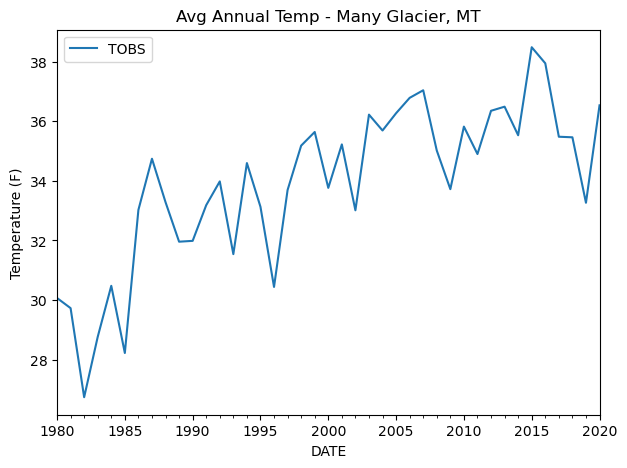

In [8]:
# STEP 6: Plot 1980-2020 data
avg_temp_1980_2020.plot(y='TOBS', figsize=(7,5),
                            ylabel='Temperature (F)',
                            title='Avg Annual Temp - Many Glacier, MT')

In [ ]:
# STEP 7: Resetting the index
[VARIALBE_FROM_STEP_5] = [VARIALBE_FROM_STEP_5].reset_index()
[VARIALBE_FROM_STEP_5]

In [ ]:
# STEP 8: Remove year from DATE column and add as new variable
[VARIALBE_FROM_STEP_5]['YEAR'] = [VARIALBE_FROM_STEP_5]['DATE'].dt.year
[VARIALBE_FROM_STEP_5]

In [ ]:
# STEP 9: Plotting with a trendline (OPTIONAL IF TIME ALLOWS)
# Define our figure and axis objects
fig, ax = plt.subplots(figsize=(6,4))

# Compute linear regression
x = [VARIALBE_FROM_STEP_5]['YEAR']
y = [VARIALBE_FROM_STEP_5]['TOBS']

# Compute the slope (m) and intercept (b) of the line y = mx + b
m, b = np.polyfit(x, y, 1)

# Define degree symbol
degree_symbol = '\u00B0'

# Plot TOBS vs. YEAR as scatter plot
ax.scatter(x, y, color='white', edgecolor='black')

# Plot line graph
ax.plot([VARIALBE_FROM_STEP_5]['YEAR'],
        [VARIALBE_FROM_STEP_5]['TOBS'],
        color='grey')

# Plot trend line
ax.plot(x, m*x + b, color='tomato', label=f'Trend Line (Slope = {m:.2f} {degree_symbol}F/yr)')

# Add legend
ax.legend()

# Add title and axis label
ax.set(title="Mean Annual Temperature\nMany Glacier, MT (1980-2020)",
       ylabel="Temperature (\u00B0F)")

plt.show()

***

# **NOW IT'S YOUR TURN!**
Try to recreate this workflow for another weather station of your choice. You can create new code cells below to get started (**HINT**: hover your mouse over the center of the screen below this cell and select the `+ Code` button). You can try copying and pasting the code you wrote for Many Glacier, MT and making changes. Be careful with copy/paste and double-check for errors before running your code.

Check the NOAA NCEI Climate Data Online **Search Tool** for a site/station that is interesting to you: https://www.ncei.noaa.gov/cdo-web/


Have fun!